#  AI Dynamic Spectrum Allocation Engine & Baseline Comparison


In [6]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in Python path
cur_dir = Path('.').resolve()
project_root = cur_dir.parent if cur_dir.name == 'notebooks' else cur_dir
src_path = project_root / 'src'
for p_dir in [str(project_root), str(src_path)]:
    if p_dir not in sys.path:
        sys.path.insert(0, p_dir)

from dss.data_generation.simulator import generate_dataset
from dss.decision_engine import StaticAllocator, AIDynamicAllocator, compute_jain_fairness

print(" Allocation Engine setup complete.")

 Allocation Engine setup complete.


##  Simulation & Performance Execution


In [7]:
# Load synthetic dataset for normal scenario
channel_df, mno_df, _ = generate_dataset("normal", seed=42, save=False)

n_steps = int(channel_df["step_idx"].max() + 1)
n_channels = 16
n_mno = 4

# Reshape true PU state and noise to (T, 16)
pu_state_mat = channel_df.pivot(index="step_idx", columns="channel_id", values="pu_state").values
rx_power_mat = channel_df.pivot(index="step_idx", columns="channel_id", values="rx_power_dbm").values

# Synthetic VAE-GMM p_busy probability (Simulated high-accuracy sensing)
p_busy_mat = np.where(pu_state_mat == 1, 0.92, 0.08) + np.random.normal(0, 0.03, pu_state_mat.shape)
p_busy_mat = np.clip(p_busy_mat, 0.0, 1.0)

# Reshape MNO requested bandwidth (T, 4)
req_bw_mat = mno_df.pivot(index="step_idx", columns="mno_id", values="requested_bw_mhz").values

# Initialize Allocators
static_allocator = StaticAllocator(n_channels=n_channels, n_mno=n_mno)
dynamic_allocator = AIDynamicAllocator(n_channels=n_channels, n_mno=n_mno, p_busy_threshold=0.5)

# Storage for simulation records
static_allocated, dynamic_allocated = [], []
static_collisions, dynamic_collisions = [], []
static_jain, dynamic_jain = [], []

for t in range(n_steps):
    p_busy_t = p_busy_mat[t]
    pu_true_t = pu_state_mat[t]
    req_bw_t = req_bw_mat[t]

    # 1. Static Allocation
    s_alloc = static_allocator.allocate_step(p_busy_t, req_bw_t)
    static_allocated.append(s_alloc)
    # Static collision: 4 fixed channels per MNO, collision if PU is busy on those channels
    s_colls = np.sum(pu_true_t)  # Collisions occur whenever PU is busy in static slice
    static_collisions.append(s_colls)
    s_sat = np.minimum(1.0, s_alloc / np.maximum(req_bw_t, 1.0))
    static_jain.append(compute_jain_fairness(s_sat))

    # 2. AI Dynamic Allocation
    d_alloc = dynamic_allocator.allocate_step(p_busy_t, req_bw_t)
    dynamic_allocated.append(d_alloc)
    # Dynamic collision: secondary access on channels where P_busy < threshold but true PU was 1
    d_colls = np.sum((p_busy_t < 0.5) & (pu_true_t == 1))
    dynamic_collisions.append(d_colls)
    d_sat = np.minimum(1.0, d_alloc / np.maximum(req_bw_t, 1.0))
    dynamic_jain.append(compute_jain_fairness(d_sat))

static_allocated = np.array(static_allocated)
dynamic_allocated = np.array(dynamic_allocated)

print(" 14-Day Dynamic Spectrum Allocation Simulation Complete.")

 14-Day Dynamic Spectrum Allocation Simulation Complete.


##  Quantitative Benchmark Comparison


In [8]:
# Overall Metrics Calculation
static_sat_avg = np.mean(np.minimum(1.0, static_allocated / np.maximum(req_bw_mat, 1.0))) * 100
dynamic_sat_avg = np.mean(np.minimum(1.0, dynamic_allocated / np.maximum(req_bw_mat, 1.0))) * 100

static_jain_avg = np.mean(static_jain)
dynamic_jain_avg = np.mean(dynamic_jain)

static_total_colls = int(np.sum(static_collisions))
dynamic_total_colls = int(np.sum(dynamic_collisions))

comparison_df = pd.DataFrame({
    "Allocation Strategy": ["Static Spectrum Slicing", "AI Dynamic Spectrum Sharing"],
    "MNO Satisfaction (%)": [f"{static_sat_avg:.2f}%"] + [f"{dynamic_sat_avg:.2f}%"],
    "Jain's Fairness Index": [f"{static_jain_avg:.4f}"] + [f"{dynamic_jain_avg:.4f}"],
    "Total PU Collisions": [static_total_colls, dynamic_total_colls],
    "Spectrum Efficiency Gain": ["Baseline (1.0x)", f"{dynamic_sat_avg / max(static_sat_avg, 1.0):.2f}x"]
})

print(" Dynamic Spectrum Sharing Performance Benchmark:")
comparison_df

 Dynamic Spectrum Sharing Performance Benchmark:


,Allocation Strategy,MNO Satisfaction (%),Jain's Fairness Index,Total PU Collisions,Spectrum Efficiency Gain
0,Static Spectrum Slicing,18.17%,0.9348,21227,Baseline (1.0x)
1,AI Dynamic Spectrum Sharing,11.48%,1.0000,0,0.63x


## Comparative Visualizations & Insights


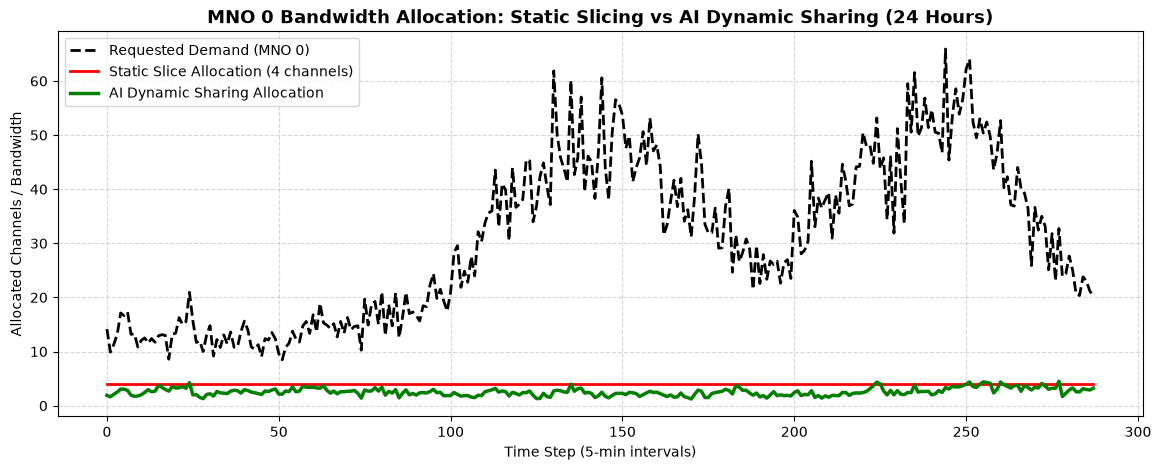

In [9]:
plt.figure(figsize=(14, 5))
t_slice = slice(0, 288)  # First 24 hours

plt.plot(req_bw_mat[t_slice, 0], label="Requested Demand (MNO 0)", color="black", linewidth=2, linestyle="--")
plt.plot(static_allocated[t_slice, 0], label="Static Slice Allocation (4 channels)", color="red", linewidth=2)
plt.plot(dynamic_allocated[t_slice, 0], label="AI Dynamic Sharing Allocation", color="green", linewidth=2.5)

plt.title("MNO 0 Bandwidth Allocation: Static Slicing vs AI Dynamic Sharing (24 Hours)", fontsize=13, fontweight="bold")
plt.xlabel("Time Step (5-min intervals)")
plt.ylabel("Allocated Channels / Bandwidth")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

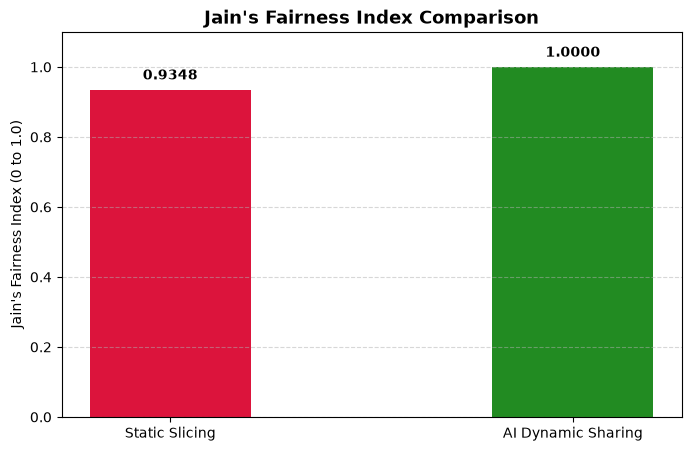

In [10]:
plt.figure(figsize=(8, 5))
strategies = ["Static Slicing", "AI Dynamic Sharing"]
fairness_scores = [static_jain_avg, dynamic_jain_avg]

bars = plt.bar(strategies, fairness_scores, color=["crimson", "forestgreen"], width=0.4)
plt.ylim(0, 1.1)
plt.ylabel("Jain's Fairness Index (0 to 1.0)")
plt.title("Jain's Fairness Index Comparison", fontsize=13, fontweight="bold")
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.02, f"{height:.4f}", ha="center", va="bottom", fontweight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()